In [ ]:
!pip install requests pandas numpy scikit-learn schedule

In [ ]:
#Import libraries
import requests
import pandas as pd
import numpy as np
import sqlite3
import logging
import time
from datetime import datetime, timedelta
from sklearn.cluster import KMeans

In [ ]:
#Test the API
import requests

url = "https://disease.sh/v3/covid-19/all"

response = requests.get(url, timeout=15)

print("Status Code:", response.status_code)

if response.status_code == 200:
    print("API connection successful!")
else:
    print("API connection failed!")

Status Code: 200
API connection successful!


In [ ]:
# API Endpoint Configuration

API_BASE = "https://disease.sh/v3/covid-19"

ENDPOINTS = {
    "worldwide": f"{API_BASE}/all",
    "historical_worldwide": f"{API_BASE}/historical/all?lastdays=all",
    "vaccine_coverage": f"{API_BASE}/vaccine/coverage/countries?lastdays=1"
}

for name, url in ENDPOINTS.items():
    print(f"{name}:")
    print(url)
    print()

worldwide:
https://disease.sh/v3/covid-19/all

historical_worldwide:
https://disease.sh/v3/covid-19/historical/all?lastdays=all

vaccine_coverage:
https://disease.sh/v3/covid-19/vaccine/coverage/countries?lastdays=1



In [ ]:
# 1. Worldwide Current COVID-19 Data

url = "https://disease.sh/v3/covid-19/all"

try:
    response = requests.get(url, timeout=15)
    response.raise_for_status()

    worldwide_data = response.json()

    print("Status Code:", response.status_code)
    print("Data Type:", type(worldwide_data))
    print("Available Fields:")
    print(worldwide_data.keys())

except requests.exceptions.RequestException as e:
    print("Error:", e)
print("Total Cases:", worldwide_data.get("cases"))
print("Total Deaths:", worldwide_data.get("deaths"))
print("Total Recovered:", worldwide_data.get("recovered"))
print("Today's Cases:", worldwide_data.get("todayCases"))
print("Today's Deaths:", worldwide_data.get("todayDeaths"))

Status Code: 200
Data Type: <class 'dict'>
Available Fields:
dict_keys(['updated', 'cases', 'todayCases', 'deaths', 'todayDeaths', 'recovered', 'todayRecovered', 'active', 'critical', 'casesPerOneMillion', 'deathsPerOneMillion', 'tests', 'testsPerOneMillion', 'population', 'oneCasePerPeople', 'oneDeathPerPeople', 'oneTestPerPeople', 'activePerOneMillion', 'recoveredPerOneMillion', 'criticalPerOneMillion', 'affectedCountries'])
Total Cases: 704753890
Total Deaths: 7010681
Total Recovered: 675619811
Today's Cases: 0
Today's Deaths: 0


In [ ]:
import requests

# 2. Worldwide Historical COVID-19 Data

url = "https://disease.sh/v3/covid-19/historical/all?lastdays=all"

try:
    response = requests.get(url, timeout=15)
    response.raise_for_status()

    global_history = response.json()

    print("Status Code:", response.status_code)
    print("Available Sections:", global_history.keys())

except requests.exceptions.RequestException as e:
    print("Error:", e)
global_cases = global_history["cases"]
global_deaths = global_history["deaths"]

print("Number of case dates:", len(global_cases))
print("Number of death dates:", len(global_deaths))

print("\nLast 5 case records:")
print(list(global_cases.items())[-5:])

Status Code: 200
Available Sections: dict_keys(['cases', 'deaths', 'recovered'])
Number of case dates: 1143
Number of death dates: 1143

Last 5 case records:
[('3/5/23', 676024901), ('3/6/23', 676082941), ('3/7/23', 676213378), ('3/8/23', 676392824), ('3/9/23', 676570149)]


In [ ]:
# 3. COVID-19 Vaccine Coverage Data

url = "https://disease.sh/v3/covid-19/vaccine/coverage/countries?lastdays=1"

try:
    response = requests.get(url, timeout=15)
    response.raise_for_status()

    vaccine_data = response.json()

    print("Status Code:", response.status_code)
    print("Data Type:", type(vaccine_data))
    print("Number of countries:", len(vaccine_data))

except requests.exceptions.RequestException as e:
    print("Error:", e)
print(vaccine_data[0])
print("\nFirst 5 vaccine records:")

for record in vaccine_data[:5]:
    print(record)

Status Code: 200
Data Type: <class 'list'>
Number of countries: 217
{'country': 'Afghanistan', 'timeline': {'7/21/25': 22964750}}

First 5 vaccine records:
{'country': 'Afghanistan', 'timeline': {'7/21/25': 22964750}}
{'country': 'Albania', 'timeline': {'7/21/25': 3088966}}
{'country': 'Algeria', 'timeline': {'7/21/25': 15267442}}
{'country': 'Andorra', 'timeline': {'7/21/25': 157072}}
{'country': 'Angola', 'timeline': {'7/21/25': 27819132}}


In [ ]:
#It returned the country snapshot, including cases, deaths, active cases, and population.
import requests

def fetch_snapshot(country):
    """
    Fetch the current COVID-19 snapshot
    for a specified country.
    """

    url = f"https://disease.sh/v3/covid-19/countries/{country}"

    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()

        data = response.json()

        return data

    except requests.exceptions.RequestException as e:
        print(f"Error fetching {country}: {e}")
        return None
india_snapshot = fetch_snapshot("India")

if india_snapshot:
    print("Country:", india_snapshot["country"])
    print("Total Cases:", india_snapshot["cases"])
    print("Total Deaths:", india_snapshot["deaths"])
    print("Active Cases:", india_snapshot["active"])
    print("Population:", india_snapshot["population"])

Country: India
Total Cases: 45035393
Total Deaths: 533570
Active Cases: 44501823
Population: 1406631776


In [ ]:
def fetch_historical(country, days="all"):
    """
    Fetch historical cumulative COVID-19 cases
    and deaths for a country.
    """

    url = (
        f"https://disease.sh/v3/covid-19/"
        f"historical/{country}?lastdays={days}"
    )

    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()

        data = response.json()

        return data

    except requests.exceptions.RequestException as e:
        print(f"Historical fetch failed for {country}: {e}")
        return None

india_history = fetch_historical("India")

if india_history:
    print("Country:", india_history["country"])
    print("Available dates:", len(india_history["timeline"]["cases"]))
    print("Historical function working!")

Country: India
Available dates: 1143
Historical function working!


In [ ]:
import time
import logging

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s"
)

def fetch_snapshot(country, retries=3):

    url = f"https://disease.sh/v3/covid-19/countries/{country}"

    for attempt in range(retries):

        try:
            response = requests.get(url, timeout=15)
            response.raise_for_status()

            logging.info(f"Snapshot fetched: {country}")
            return response.json()

        except requests.exceptions.RequestException as e:

            logging.warning(
                f"Attempt {attempt + 1} failed for {country}: {e}"
            )

            if attempt < retries - 1:
                time.sleep(2 ** attempt)

    logging.error(f"All retries failed for {country}")
    return None
test_history = fetch_historical("India")

if test_history:
    print("Historical fetch successful!")

Historical fetch successful!


In [ ]:
#Global snapshot DataFrame

global_snapshot = pd.DataFrame([worldwide_data])

print("Shape:", global_snapshot.shape)
print("\nColumns:")
print(global_snapshot.columns.tolist())

print("\nPreview:")
display(global_snapshot.head())

Shape: (1, 21)

Columns:
['updated', 'cases', 'todayCases', 'deaths', 'todayDeaths', 'recovered', 'todayRecovered', 'active', 'critical', 'casesPerOneMillion', 'deathsPerOneMillion', 'tests', 'testsPerOneMillion', 'population', 'oneCasePerPeople', 'oneDeathPerPeople', 'oneTestPerPeople', 'activePerOneMillion', 'recoveredPerOneMillion', 'criticalPerOneMillion', 'affectedCountries']

Preview:


,updated,cases,todayCases,deaths,todayDeaths,recovered,todayRecovered,active,critical,casesPerOneMillion,...,tests,testsPerOneMillion,population,oneCasePerPeople,oneDeathPerPeople,oneTestPerPeople,activePerOneMillion,recoveredPerOneMillion,criticalPerOneMillion,affectedCountries
0,1790689906933,704753890,0,7010681,0,675619811,790,22123398,34794,90413,...,7026505313,884400.59,7944935131,0,0,0,2784.59,85037.8,4.38,231


In [ ]:
#Global historical DataFrame
# Global Historical DataFrame

global_history_df = pd.DataFrame({
    "date": list(global_cases.keys()),
    "cumulative_cases": list(global_cases.values()),
    "cumulative_deaths": list(global_deaths.values())
})

# Convert date column
global_history_df["date"] = pd.to_datetime(
    global_history_df["date"],
    format="%m/%d/%y"
)

# Sort by date
global_history_df = global_history_df.sort_values("date").reset_index(drop=True)

print("Shape:", global_history_df.shape)

display(global_history_df.head())
display(global_history_df.tail())

Shape: (1143, 3)


,date,cumulative_cases,cumulative_deaths
0,2020-01-22,557,17
1,2020-01-23,657,18
2,2020-01-24,944,26
3,2020-01-25,1437,42
4,2020-01-26,2120,56


,date,cumulative_cases,cumulative_deaths
1138,2023-03-05,676024901,6877749
1139,2023-03-06,676082941,6878115
1140,2023-03-07,676213378,6879038
1141,2023-03-08,676392824,6880483
1142,2023-03-09,676570149,6881802


In [ ]:
#Create daily cases and deaths
# Convert cumulative values into daily values

global_history_df["new_cases"] = (
    global_history_df["cumulative_cases"]
    .diff()
    .fillna(0)
)

global_history_df["new_deaths"] = (
    global_history_df["cumulative_deaths"]
    .diff()
    .fillna(0)
)

# Remove negative values caused by historical data revisions
global_history_df["new_cases"] = global_history_df["new_cases"].clip(lower=0)
global_history_df["new_deaths"] = global_history_df["new_deaths"].clip(lower=0)

display(global_history_df.tail(10))

,date,cumulative_cases,cumulative_deaths,new_cases,new_deaths
1133,2023-02-28,675322238,6872682,150799.0,874.0
1134,2023-03-01,675542852,6874463,220614.0,1781.0
1135,2023-03-02,675731911,6876031,189059.0,1568.0
1136,2023-03-03,675914580,6877325,182669.0,1294.0
1137,2023-03-04,675968775,6877601,54195.0,276.0
1138,2023-03-05,676024901,6877749,56126.0,148.0
1139,2023-03-06,676082941,6878115,58040.0,366.0
1140,2023-03-07,676213378,6879038,130437.0,923.0
1141,2023-03-08,676392824,6880483,179446.0,1445.0
1142,2023-03-09,676570149,6881802,177325.0,1319.0


In [ ]:
#7-day rolling average
# 7-Day Rolling Average

global_history_df["cases_7d_avg"] = (
    global_history_df["new_cases"]
    .rolling(window=7)
    .mean()
)

global_history_df["deaths_7d_avg"] = (
    global_history_df["new_deaths"]
    .rolling(window=7)
    .mean()
)

display(global_history_df.tail(10))

,date,cumulative_cases,cumulative_deaths,new_cases,new_deaths,cases_7d_avg,deaths_7d_avg
1133,2023-02-28,675322238,6872682,150799.0,874.0,142645.285714,942.000000
1134,2023-03-01,675542852,6874463,220614.0,1781.0,139004.000000,936.285714
1135,2023-03-02,675731911,6876031,189059.0,1568.0,134427.857143,887.714286
1136,2023-03-03,675914580,6877325,182669.0,1294.0,140176.857143,931.285714
1137,2023-03-04,675968775,6877601,54195.0,276.0,141426.000000,939.571429
1138,2023-03-05,676024901,6877749,56126.0,148.0,140069.571429,925.857143
1139,2023-03-06,676082941,6878115,58040.0,366.0,130214.571429,901.000000
1140,2023-03-07,676213378,6879038,130437.0,923.0,127305.714286,908.000000
1141,2023-03-08,676392824,6880483,179446.0,1445.0,121424.571429,860.000000
1142,2023-03-09,676570149,6881802,177325.0,1319.0,119748.285714,824.428571


In [ ]:
# Vaccine Coverage DataFrame

vaccine_records = []

for record in vaccine_data:
    country = record["country"]

    for date, coverage in record["timeline"].items():
        vaccine_records.append({
            "country": country,
            "date": pd.to_datetime(date),
            "vaccine_coverage": coverage
        })

vaccine_df = pd.DataFrame(vaccine_records)

print("Shape:", vaccine_df.shape)
print("\nNumber of countries:", vaccine_df["country"].nunique())

display(vaccine_df.head())

Shape: (217, 3)

Number of countries: 217


,country,date,vaccine_coverage
0,Afghanistan,2025-07-21,22964750
1,Albania,2025-07-21,3088966
2,Algeria,2025-07-21,15267442
3,Andorra,2025-07-21,157072
4,Angola,2025-07-21,27819132


In [ ]:
# Fixed country watchlist
#Choose a fixed watch-list of 15–20 countries (mix of high-, middle-, low-income for a more interesting
#comparison) rather than pulling all ~200 — document why you chose them.
WATCHLIST = [
    "India",
    "United States",
    "Brazil",
    "United Kingdom",
    "Germany",
    "France",
    "Italy",
    "Japan",
    "South Korea",
    "China",
    "South Africa",
    "Nigeria",
    "Indonesia",
    "Mexico",
    "Canada",
    "Australia",
    "Bangladesh",
    "Pakistan",
    "Nepal",
    "Sri Lanka"
]

print("Number of countries:", len(WATCHLIST))

print("\nCountries:")
for country in WATCHLIST:
    print("-", country)

Number of countries: 20

Countries:
- India
- United States
- Brazil
- United Kingdom
- Germany
- France
- Italy
- Japan
- South Korea
- China
- South Africa
- Nigeria
- Indonesia
- Mexico
- Canada
- Australia
- Bangladesh
- Pakistan
- Nepal
- Sri Lanka


In [ ]:
#get_country_history() function
def get_country_history(country, days="all"):
    """
    Fetch historical COVID-19 data for a country
    from the disease.sh API.
    """

    url = f"https://disease.sh/v3/covid-19/historical/{country}?lastdays={days}"

    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()

        data = response.json()

        return data

    except requests.exceptions.RequestException as e:
        print(f"Error fetching data for {country}: {e}")
        return None

In [ ]:
#the 20-country fetching cell
country_records = []

for country in WATCHLIST:

    print(f"Fetching: {country}")

    data = get_country_history(country)

    if data is None:
        print(f"Failed: {country}")
        continue

    timeline = data["timeline"]

    cases = timeline["cases"]
    deaths = timeline["deaths"]

    for date in cases.keys():

        country_records.append({
            "country": country,
            "date": date,
            "cumulative_cases": cases[date],
            "cumulative_deaths": deaths.get(date, 0)
        })

print("\nTotal records collected:", len(country_records))

Fetching: India
Fetching: United States
Fetching: Brazil
Fetching: United Kingdom
Fetching: Germany
Fetching: France
Fetching: Italy
Fetching: Japan
Fetching: South Korea
Fetching: China
Fetching: South Africa
Fetching: Nigeria
Fetching: Indonesia
Fetching: Mexico
Fetching: Canada
Fetching: Australia
Fetching: Bangladesh
Fetching: Pakistan
Fetching: Nepal
Fetching: Sri Lanka

Total records collected: 22860


In [ ]:
# Create the 20-country historical DataFrame

country_history_df = pd.DataFrame(country_records)

# Convert date from text to datetime
country_history_df["date"] = pd.to_datetime(
    country_history_df["date"],
    format="%m/%d/%y"
)

# Sort by country and date
country_history_df = country_history_df.sort_values(
    ["country", "date"]
).reset_index(drop=True)

print("Shape:", country_history_df.shape)

print("\nNumber of countries:",
      country_history_df["country"].nunique())

print("\nColumns:")
print(country_history_df.columns.tolist())

display(country_history_df.head(10))

Shape: (22860, 4)

Number of countries: 20

Columns:
['country', 'date', 'cumulative_cases', 'cumulative_deaths']


,country,date,cumulative_cases,cumulative_deaths
0,Australia,2020-01-22,0,0
1,Australia,2020-01-23,0,0
2,Australia,2020-01-24,0,0
3,Australia,2020-01-25,0,0
4,Australia,2020-01-26,4,0
5,Australia,2020-01-27,5,0
6,Australia,2020-01-28,5,0
7,Australia,2020-01-29,6,0
8,Australia,2020-01-30,9,0
9,Australia,2020-01-31,9,0


In [ ]:
# Calculate daily new cases and deaths for each country

country_history_df["new_cases"] = (
    country_history_df
    .groupby("country")["cumulative_cases"]
    .diff()
    .fillna(0)
)

country_history_df["new_deaths"] = (
    country_history_df
    .groupby("country")["cumulative_deaths"]
    .diff()
    .fillna(0)
)

# Remove negative values caused by historical reporting revisions
country_history_df["new_cases"] = (
    country_history_df["new_cases"].clip(lower=0)
)

country_history_df["new_deaths"] = (
    country_history_df["new_deaths"].clip(lower=0)
)

print("Daily cases and deaths calculated successfully!")

display(country_history_df.head(10))

Daily cases and deaths calculated successfully!


,country,date,cumulative_cases,cumulative_deaths,new_cases,new_deaths
0,Australia,2020-01-22,0,0,0.0,0.0
1,Australia,2020-01-23,0,0,0.0,0.0
2,Australia,2020-01-24,0,0,0.0,0.0
3,Australia,2020-01-25,0,0,0.0,0.0
4,Australia,2020-01-26,4,0,4.0,0.0
5,Australia,2020-01-27,5,0,1.0,0.0
6,Australia,2020-01-28,5,0,0.0,0.0
7,Australia,2020-01-29,6,0,1.0,0.0
8,Australia,2020-01-30,9,0,3.0,0.0
9,Australia,2020-01-31,9,0,0.0,0.0


In [ ]:
# BASIC PANDAS - DESCRIPTIVE STATISTICS

print("=== GLOBAL HISTORICAL ===")
display(global_history_df.describe())

print("\n=== VACCINE COVERAGE ===")
display(vaccine_df.describe())

print("\n=== COUNTRY HISTORICAL ===")
display(country_history_df[
    ["cumulative_cases", "cumulative_deaths", "new_cases", "new_deaths"]
].describe())

=== GLOBAL HISTORICAL ===


,date,cumulative_cases,cumulative_deaths,new_cases,new_deaths,cases_7d_avg,deaths_7d_avg
count,1143,1.143000e+03,1.143000e+03,1.143000e+03,1143.000000,1.137000e+03,1137.000000
mean,2021-08-15 00:00:00,2.772619e+08,3.866856e+06,5.919244e+05,6020.809274,5.946926e+05,6049.988064
min,2020-01-22 00:00:00,5.570000e+02,1.700000e+01,0.000000e+00,0.000000,7.175714e+02,16.285714
25%,2020-11-02 12:00:00,4.742606e+07,1.282415e+06,2.651960e+05,2177.000000,2.908400e+05,2083.714286
50%,2021-08-15 00:00:00,2.078154e+08,4.388700e+06,4.725230e+05,5839.000000,4.888191e+05,6069.000000
75%,2022-05-27 12:00:00,5.288307e+08,6.312702e+06,6.767740e+05,8773.000000,6.462504e+05,9218.142857
max,2023-03-09 00:00:00,6.765701e+08,6.881802e+06,4.083281e+06,60903.000000,3.436897e+06,14855.000000
std,NaN,2.397757e+08,2.436775e+06,5.956479e+05,4451.960422,5.695728e+05,3880.696275



=== VACCINE COVERAGE ===


,date,vaccine_coverage
count,217,2.170000e+02
mean,2025-07-21 00:00:00,6.256256e+07
min,2025-07-21 00:00:00,1.170000e+02
25%,2025-07-21 00:00:00,7.376950e+05
50%,2025-07-21 00:00:00,5.922585e+06
75%,2025-07-21 00:00:00,2.640694e+07
max,2025-07-21 00:00:00,3.491077e+09
std,NaN,2.891027e+08



=== COUNTRY HISTORICAL ===


,cumulative_cases,cumulative_deaths,new_cases,new_deaths
count,2.286000e+04,2.286000e+04,2.286000e+04,22860.000000
mean,8.431006e+06,1.147305e+05,1.851229e+04,177.969379
std,1.598501e+07,2.011846e+05,5.016406e+04,591.534111
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,1.996212e+05,4.712000e+03,1.317500e+02,1.000000
50%,1.561209e+06,2.862250e+04,1.767000e+03,24.000000
75%,7.036371e+06,1.426742e+05,1.379150e+04,134.000000
max,1.038027e+08,1.123836e+06,1.354505e+06,59961.000000


In [ ]:
# BASIC PANDAS - UNIQUE VALUES AND FREQUENCY

print("=== COUNTRY HISTORICAL ===")

print("Number of Countries:",
      country_history_df["country"].nunique())

print("\nRecords per Country:")
display(country_history_df["country"].value_counts())

print("\n=== VACCINE COVERAGE ===")

print("Number of Countries:",
      vaccine_df["country"].nunique())

print("\nVaccine Records per Country:")
display(vaccine_df["country"].value_counts().head(10))

print("\n=== GLOBAL HISTORICAL ===")

print("Number of Dates:",
      global_history_df["date"].nunique())

=== COUNTRY HISTORICAL ===
Number of Countries: 20

Records per Country:


,count
country,
Australia,1143
Bangladesh,1143
Brazil,1143
Canada,1143
China,1143
France,1143
Germany,1143
India,1143
Indonesia,1143



=== VACCINE COVERAGE ===
Number of Countries: 217

Vaccine Records per Country:


,count
country,
Afghanistan,1
Albania,1
Algeria,1
Andorra,1
Angola,1
Anguilla,1
Antigua and Barbuda,1
Argentina,1
Armenia,1



=== GLOBAL HISTORICAL ===
Number of Dates: 1143


In [ ]:
# BASIC PANDAS - SHAPE, COLUMNS AND DATA TYPES

datasets = {
    "Global Snapshot": global_snapshot,
    "Global Historical": global_history_df,
    "Vaccine Coverage": vaccine_df,
    "Country Historical": country_history_df
}

for name, df in datasets.items():
    print("\n==============================")
    print(name)
    print("==============================")

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nData Types:")
    print(df.dtypes)


Global Snapshot
Shape: (1, 21)
Columns: ['updated', 'cases', 'todayCases', 'deaths', 'todayDeaths', 'recovered', 'todayRecovered', 'active', 'critical', 'casesPerOneMillion', 'deathsPerOneMillion', 'tests', 'testsPerOneMillion', 'population', 'oneCasePerPeople', 'oneDeathPerPeople', 'oneTestPerPeople', 'activePerOneMillion', 'recoveredPerOneMillion', 'criticalPerOneMillion', 'affectedCountries']

Data Types:
updated                     int64
cases                       int64
todayCases                  int64
deaths                      int64
todayDeaths                 int64
recovered                   int64
todayRecovered              int64
active                      int64
critical                    int64
casesPerOneMillion          int64
deathsPerOneMillion       float64
tests                       int64
testsPerOneMillion        float64
population                  int64
oneCasePerPeople            int64
oneDeathPerPeople           int64
oneTestPerPeople            int64
activePer

In [ ]:
# BASIC PANDAS - MISSING VALUES AND DUPLICATES

datasets = {
    "Global Snapshot": global_snapshot,
    "Global Historical": global_history_df,
    "Vaccine Coverage": vaccine_df,
    "Country Historical": country_history_df
}

for name, df in datasets.items():
    print("\n==============================")
    print(name)
    print("==============================")

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:", df.duplicated().sum())


Global Snapshot

Missing Values:
updated                   0
cases                     0
todayCases                0
deaths                    0
todayDeaths               0
recovered                 0
todayRecovered            0
active                    0
critical                  0
casesPerOneMillion        0
deathsPerOneMillion       0
tests                     0
testsPerOneMillion        0
population                0
oneCasePerPeople          0
oneDeathPerPeople         0
oneTestPerPeople          0
activePerOneMillion       0
recoveredPerOneMillion    0
criticalPerOneMillion     0
affectedCountries         0
dtype: int64

Duplicate Rows: 0

Global Historical

Missing Values:
date                 0
cumulative_cases     0
cumulative_deaths    0
new_cases            0
new_deaths           0
cases_7d_avg         6
deaths_7d_avg        6
dtype: int64

Duplicate Rows: 0

Vaccine Coverage

Missing Values:
country             0
date                0
vaccine_coverage    0
dtype: int64

Du

In [ ]:
# Calculate 7-day rolling averages
country_history_df["cases_7d_avg"] = (
    country_history_df
    .groupby("country")["new_cases"]
    .transform(lambda x: x.rolling(7).mean())
)
country_history_df["deaths_7d_avg"] = (
    country_history_df
    .groupby("country")["new_deaths"]
    .transform(lambda x: x.rolling(7).mean())
)
print("7-day rolling averages calculated successfully!")
# Fill missing values in 7-day rolling averages

country_history_df["cases_7d_avg"] = country_history_df["cases_7d_avg"].fillna(0)
country_history_df["deaths_7d_avg"] = country_history_df["deaths_7d_avg"].fillna(0)

print("Missing values filled successfully!")

print(country_history_df[["cases_7d_avg", "deaths_7d_avg"]].isnull().sum())
display(country_history_df.head(10))

print(country_history_df.isnull().sum())

7-day rolling averages calculated successfully!
Missing values filled successfully!
cases_7d_avg     0
deaths_7d_avg    0
dtype: int64


,country,date,cumulative_cases,cumulative_deaths,new_cases,new_deaths,cases_7d_avg,deaths_7d_avg
0,Australia,2020-01-22,0,0,0.0,0.0,0.000000,0.0
1,Australia,2020-01-23,0,0,0.0,0.0,0.000000,0.0
2,Australia,2020-01-24,0,0,0.0,0.0,0.000000,0.0
3,Australia,2020-01-25,0,0,0.0,0.0,0.000000,0.0
4,Australia,2020-01-26,4,0,4.0,0.0,0.000000,0.0
5,Australia,2020-01-27,5,0,1.0,0.0,0.000000,0.0
6,Australia,2020-01-28,5,0,0.0,0.0,0.714286,0.0
7,Australia,2020-01-29,6,0,1.0,0.0,0.857143,0.0
8,Australia,2020-01-30,9,0,3.0,0.0,1.285714,0.0
9,Australia,2020-01-31,9,0,0.0,0.0,1.285714,0.0


country              0
date                 0
cumulative_cases     0
cumulative_deaths    0
new_cases            0
new_deaths           0
cases_7d_avg         0
deaths_7d_avg        0
dtype: int64


In [ ]:
# Fetch population for each country
population_data = {}
for country in WATCHLIST:
    url = f"https://disease.sh/v3/covid-19/countries/{country}"
    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        data = response.json()
        population_data[country] = data["population"]
    except requests.exceptions.RequestException as e:
        print(f"Failed: {country} - {e}")
print("Population data collected:", len(population_data))

Population data collected: 20


In [ ]:
# Add population to the country history data

country_history_df["population"] = (
    country_history_df["country"].map(population_data)
)

# Calculate cases per million
country_history_df["cases_per_million"] = (
    country_history_df["cumulative_cases"]
    / country_history_df["population"]
    * 1_000_000
)

# Calculate deaths per million
country_history_df["deaths_per_million"] = (
    country_history_df["cumulative_deaths"]
    / country_history_df["population"]
    * 1_000_000
)

print("Cases per million and deaths per million calculated!")

display(
    country_history_df[
        ["country", "date", "population",
         "cases_per_million", "deaths_per_million"]
    ].head(10)
)

Cases per million and deaths per million calculated!


,country,date,population,cases_per_million,deaths_per_million
0,Australia,2020-01-22,26068792,0.00000,0.0
1,Australia,2020-01-23,26068792,0.00000,0.0
2,Australia,2020-01-24,26068792,0.00000,0.0
3,Australia,2020-01-25,26068792,0.00000,0.0
4,Australia,2020-01-26,26068792,0.15344,0.0
5,Australia,2020-01-27,26068792,0.19180,0.0
6,Australia,2020-01-28,26068792,0.19180,0.0
7,Australia,2020-01-29,26068792,0.23016,0.0
8,Australia,2020-01-30,26068792,0.34524,0.0
9,Australia,2020-01-31,26068792,0.34524,0.0


In [ ]:
# next is Growth Rate Analysis 7th day
# Calculate current 7-day total cases
country_history_df["cases_7d_sum"] = (
    country_history_df
    .groupby("country")["new_cases"]
    .transform(lambda x: x.rolling(7).sum())
)
# Calculate previous 7-day total cases
country_history_df["previous_7d_sum"] = (
    country_history_df
    .groupby("country")["cases_7d_sum"]
    .shift(7)
)
# Calculate 7-day growth rate
country_history_df["growth_rate"] = np.where(
    country_history_df["previous_7d_sum"] > 0,
    (
        country_history_df["cases_7d_sum"]
        / country_history_df["previous_7d_sum"] - 1
    ) * 100,
    np.nan
)
print("7-day growth rate calculated successfully!")
display(
    country_history_df[
        ["country", "date", "cases_7d_sum",
         "previous_7d_sum", "growth_rate"]
    ].tail(10)
)

7-day growth rate calculated successfully!


,country,date,cases_7d_sum,previous_7d_sum,growth_rate
22850,United States,2023-02-28,244786.0,264445.0,-7.434060
22851,United States,2023-03-01,225040.0,285601.0,-21.204758
22852,United States,2023-03-02,224246.0,281601.0,-20.367470
22853,United States,2023-03-03,270282.0,246510.0,9.643422
22854,United States,2023-03-04,269680.0,246552.0,9.380577
22855,United States,2023-03-05,268074.0,246686.0,8.670131
22856,United States,2023-03-06,259574.0,261708.0,-0.815413
22857,United States,2023-03-07,251317.0,244786.0,2.668045
22858,United States,2023-03-08,225761.0,225040.0,0.320387
22859,United States,2023-03-09,216807.0,224246.0,-3.317339


In [ ]:
# Calculate Case Fatality Ratio

country_history_df["case_fatality_ratio"] = np.where(
    country_history_df["cumulative_cases"] > 0,
    (
        country_history_df["cumulative_deaths"]
        / country_history_df["cumulative_cases"]
    ) * 100,
    0
)

print("Case Fatality Ratio calculated successfully!")

display(
    country_history_df[
        [
            "country",
            "date",
            "cumulative_cases",
            "cumulative_deaths",
            "case_fatality_ratio"
        ]
    ].tail(10)
)

Case Fatality Ratio calculated successfully!


,country,date,cumulative_cases,cumulative_deaths,case_fatality_ratio
22850,United States,2023-02-28,103443455,1119917,1.082637
22851,United States,2023-03-01,103533872,1120897,1.082638
22852,United States,2023-03-02,103589757,1121658,1.082789
22853,United States,2023-03-03,103648690,1122165,1.082662
22854,United States,2023-03-04,103650837,1122172,1.082646
22855,United States,2023-03-05,103646975,1122134,1.082650
22856,United States,2023-03-06,103655539,1122181,1.082606
22857,United States,2023-03-07,103690910,1122516,1.082560
22858,United States,2023-03-08,103755771,1123246,1.082587
22859,United States,2023-03-09,103802702,1123836,1.082665


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Create scaler
scaler = MinMaxScaler()

# Normalize the three risk factors
country_history_df[
    [
        "growth_rate_norm",
        "cases_per_million_norm",
        "cfr_norm"
    ]
] = scaler.fit_transform(
    country_history_df[
        [
            "growth_rate",
            "cases_per_million",
            "case_fatality_ratio"
        ]
    ].fillna(0)
)

print("Risk factors normalized successfully!")

display(
    country_history_df[
        [
            "country",
            "date",
            "growth_rate_norm",
            "cases_per_million_norm",
            "cfr_norm"
        ]
    ].tail(10)
)

Risk factors normalized successfully!


,country,date,growth_rate_norm,cases_per_million_norm,cfr_norm
22850,United States,2023-02-28,0.000786,0.508278,0.010826
22851,United States,2023-03-01,0.000669,0.508723,0.010826
22852,United States,2023-03-02,0.000677,0.508997,0.010828
22853,United States,2023-03-03,0.000932,0.509287,0.010827
22854,United States,2023-03-04,0.000929,0.509297,0.010826
22855,United States,2023-03-05,0.000923,0.509278,0.010827
22856,United States,2023-03-06,0.000843,0.509320,0.010826
22857,United States,2023-03-07,0.000872,0.509494,0.010826
22858,United States,2023-03-08,0.000852,0.509813,0.010826
22859,United States,2023-03-09,0.000821,0.510044,0.010827


In [ ]:
# Calculate Composite Outbreak Risk Score
country_history_df["risk_score"] = (
    country_history_df["growth_rate_norm"] * 50
    + country_history_df["cases_per_million_norm"] * 30
    + country_history_df["cfr_norm"] * 20
)
# Keep score between 0 and 100
country_history_df["risk_score"] = (
    country_history_df["risk_score"].clip(0, 100)
)

print("Risk Score calculated successfully!")

display(
    country_history_df[
        [
            "country",
            "date",
            "growth_rate",
            "cases_per_million",
            "case_fatality_ratio",
            "risk_score"
        ]
    ].tail(10)
)

Risk Score calculated successfully!


,country,date,growth_rate,cases_per_million,case_fatality_ratio,risk_score
22850,United States,2023-02-28,-7.434060,308966.030639,1.082637,15.504198
22851,United States,2023-03-01,-21.204758,309236.089113,1.082638,15.511676
22852,United States,2023-03-02,-20.367470,309403.007036,1.082789,15.520300
22853,United States,2023-03-03,9.643422,309579.028758,1.082662,15.541710
22854,United States,2023-03-04,9.380577,309585.441441,1.082646,15.541912
22855,United States,2023-03-05,8.670131,309573.906377,1.082650,15.541041
22856,United States,2023-03-06,-0.815413,309599.485425,1.082606,15.538266
22857,United States,2023-03-07,2.668045,309705.131911,1.082560,15.544950
22858,United States,2023-03-08,0.320387,309898.859447,1.082587,15.553519
22859,United States,2023-03-09,-3.317339,310039.033466,1.082665,15.558908


In [ ]:
#Curve-shape KMeans
from sklearn.cluster import KMeans

# Use the most recent 90 days of 7-day smoothed cases
recent_data = country_history_df.groupby("country").tail(90)

# Create a matrix:
# rows = countries
# columns = 90 days
cluster_data = recent_data.pivot(
    index="country",
    columns="date",
    values="cases_7d_avg"
).fillna(0)

# Min-Max normalize each country's curve
curve_normalized = cluster_data.div(
    cluster_data.max(axis=1).replace(0, 1),
    axis=0
)

# KMeans clustering
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(curve_normalized)

# Add cluster labels
cluster_result = pd.DataFrame({
    "country": curve_normalized.index,
    "cluster": cluster_labels
})

country_history_df = country_history_df.merge(
    cluster_result,
    on="country",
    how="left"
)

print("KMeans clustering completed!")

display(cluster_result)

KMeans clustering completed!


,country,cluster
0,Australia,0
1,Bangladesh,1
2,Brazil,0
3,Canada,1
4,China,0
5,France,0
6,Germany,0
7,India,1
8,Indonesia,0
9,Italy,0


In [ ]:
# Calculate z-score for daily new cases

country_history_df["cases_zscore"] = (
    country_history_df
    .groupby("country")["new_cases"]
    .transform(
        lambda x: (x - x.mean()) / x.std()
    )
)

# Flag unusual observations
country_history_df["anomaly"] = (
    country_history_df["cases_zscore"].abs() > 3
)

print("Z-score anomaly detection completed!")

display(
    country_history_df[
        [
            "country",
            "date",
            "new_cases",
            "cases_zscore",
            "anomaly"
        ]
    ].tail(10)
)

Z-score anomaly detection completed!


,country,date,new_cases,cases_zscore,anomaly
22850,United States,2023-02-28,43628.0,-0.372923,False
22851,United States,2023-03-01,90417.0,-0.003180,False
22852,United States,2023-03-02,55885.0,-0.276064,False
22853,United States,2023-03-03,58933.0,-0.251978,False
22854,United States,2023-03-04,2147.0,-0.700721,False
22855,United States,2023-03-05,0.0,-0.717687,False
22856,United States,2023-03-06,8564.0,-0.650011,False
22857,United States,2023-03-07,35371.0,-0.438173,False
22858,United States,2023-03-08,64861.0,-0.205132,False
22859,United States,2023-03-09,46931.0,-0.346822,False


In [ ]:
# 7-Day Projection

projection_results = []

for country in WATCHLIST:

    country_data = (
        country_history_df[
            country_history_df["country"] == country
        ]
        .sort_values("date")
        .tail(14)
    )

    # Day numbers: 0 to 13
    x = np.arange(len(country_data))

    # Daily new cases
    y = country_data["new_cases"].values

    # Fit linear trend
    slope, intercept = np.polyfit(x, y, 1)

    # Project next 7 days
    future_x = np.arange(14, 21)

    projected_cases = slope * future_x + intercept

    # Negative predictions are set to 0
    projected_cases = np.maximum(projected_cases, 0)

    last_date = country_data["date"].max()

    for i, cases in enumerate(projected_cases, start=1):

        projection_results.append({
            "country": country,
            "date": last_date + pd.Timedelta(days=i),
            "projected_new_cases": cases
        })

projection_df = pd.DataFrame(projection_results)

print("7-day projection completed!")

display(projection_df.head(10))

7-day projection completed!


,country,date,projected_new_cases
0,India,2023-03-10,401.648352
1,India,2023-03-11,418.096703
2,India,2023-03-12,434.545055
3,India,2023-03-13,450.993407
4,India,2023-03-14,467.441758
5,India,2023-03-15,483.890110
6,India,2023-03-16,500.338462
7,United States,2023-03-10,46176.703297
8,United States,2023-03-11,48133.092308
9,United States,2023-03-12,50089.481319


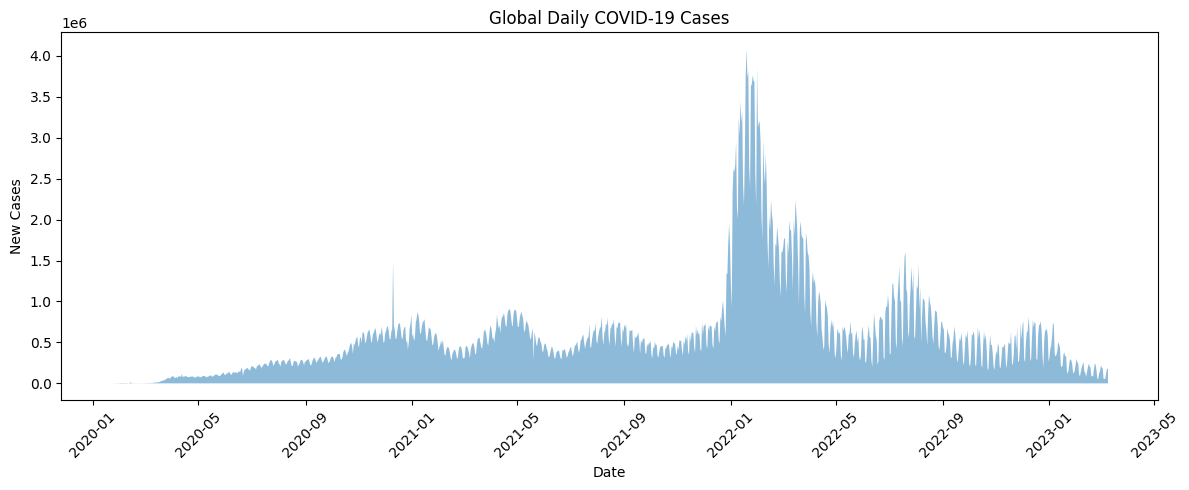

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.fill_between(
    global_history_df["date"],
    global_history_df["new_cases"],
    alpha=0.5
)

plt.title("Global Daily COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("New Cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

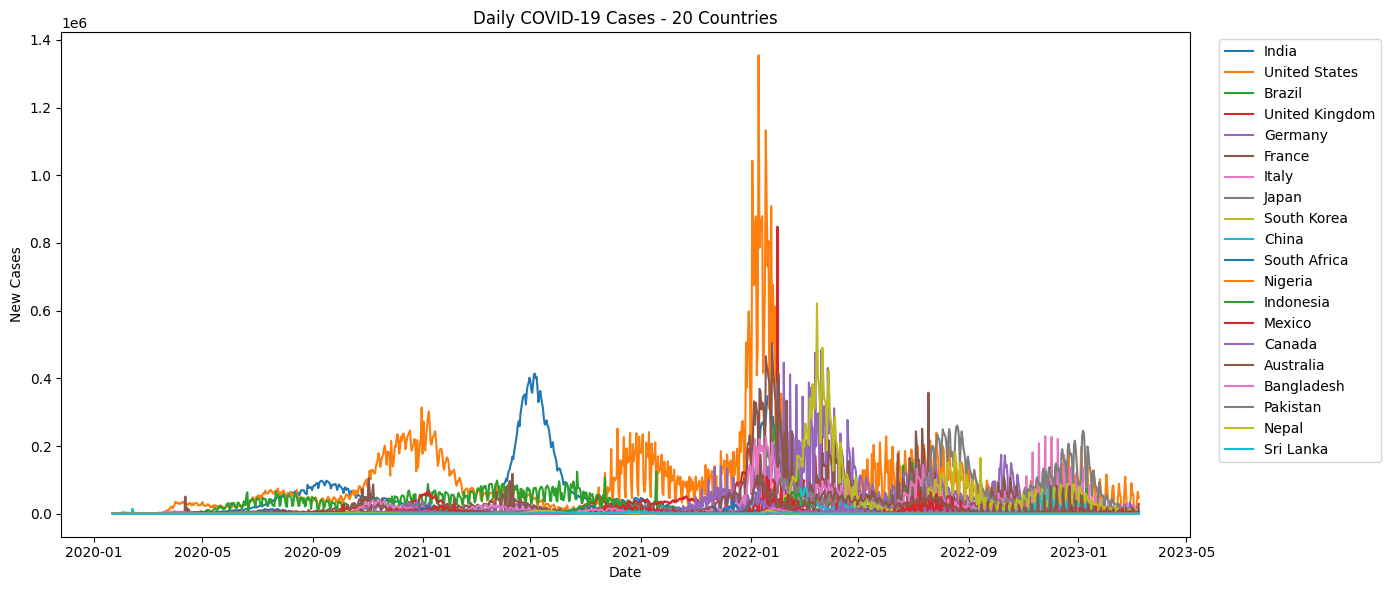

In [ ]:
# Matplotlib - Daily Cases by Country

plt.figure(figsize=(14, 6))

for country in WATCHLIST:
    data = country_history_df[
        country_history_df["country"] == country
    ]

    plt.plot(
        data["date"],
        data["new_cases"],
        label=country
    )

plt.title("Daily COVID-19 Cases - 20 Countries")
plt.xlabel("Date")
plt.ylabel("New Cases")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

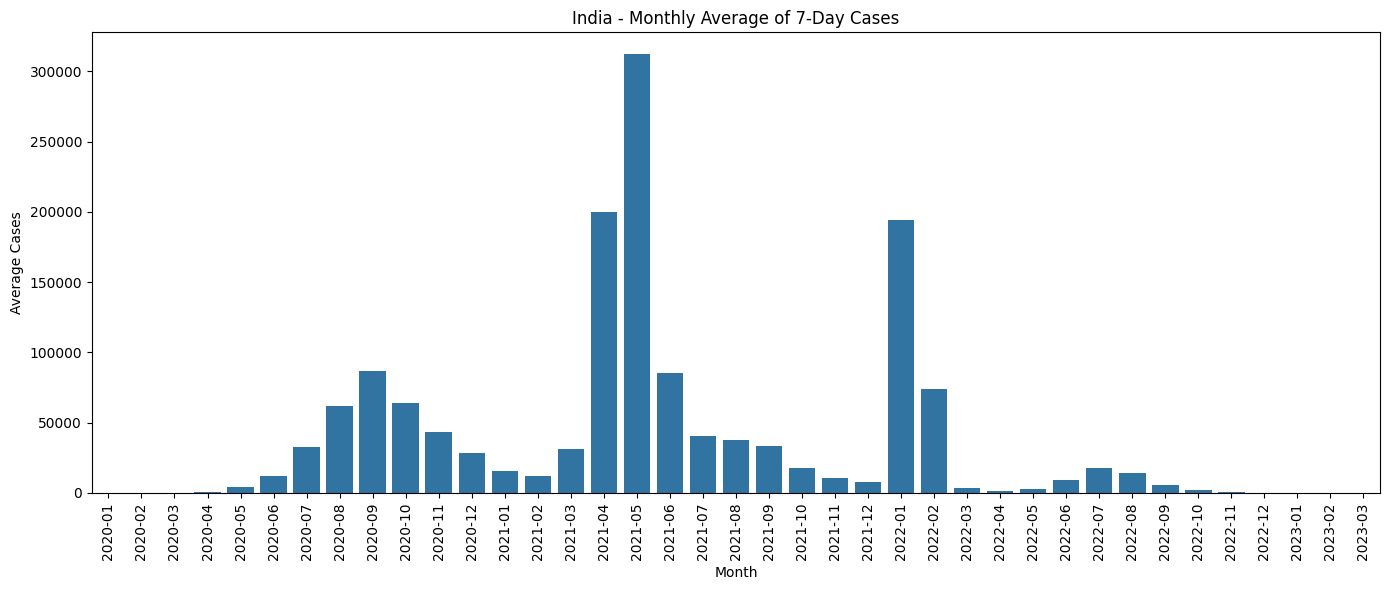

In [ ]:
import seaborn as sns

# Seaborn - Monthly Average of 7-Day Smoothed Cases

india_data = country_history_df[
    country_history_df["country"] == "India"
].copy()

india_data["month"] = india_data["date"].dt.to_period("M").astype(str)

monthly_data = (
    india_data
    .groupby("month")["cases_7d_avg"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=monthly_data,
    x="month",
    y="cases_7d_avg"
)

plt.title("India - Monthly Average of 7-Day Cases")
plt.xlabel("Month")
plt.ylabel("Average Cases")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

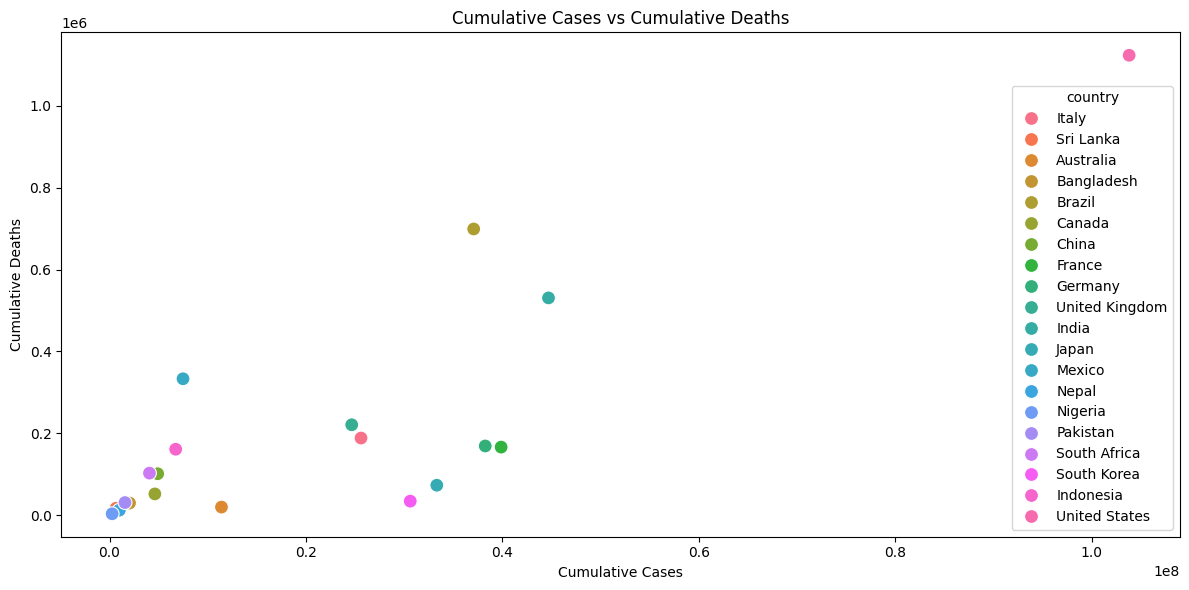

In [ ]:
# Seaborn - Cases vs Deaths

latest_country = (
    country_history_df
    .sort_values("date")
    .groupby("country")
    .tail(1)
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=latest_country,
    x="cumulative_cases",
    y="cumulative_deaths",
    hue="country",
    s=100
)

plt.title("Cumulative Cases vs Cumulative Deaths")
plt.xlabel("Cumulative Cases")
plt.ylabel("Cumulative Deaths")

plt.tight_layout()
plt.show()

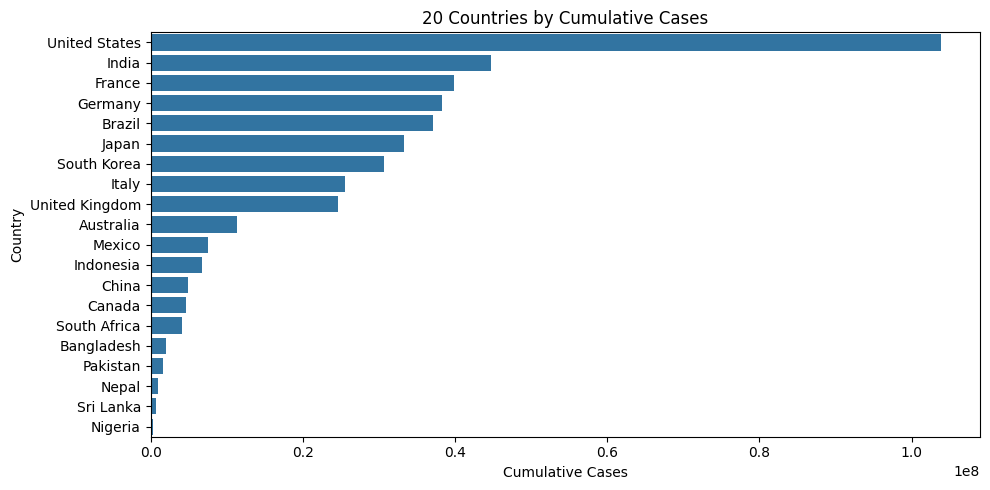

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

top_countries = (
    country_history_df
    .groupby("country")["cumulative_cases"]
    .max()
    .sort_values(ascending=False)
    .reset_index()
)
plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_countries,
    x="cumulative_cases",
    y="country"
)

plt.title("20 Countries by Cumulative Cases")
plt.xlabel("Cumulative Cases")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

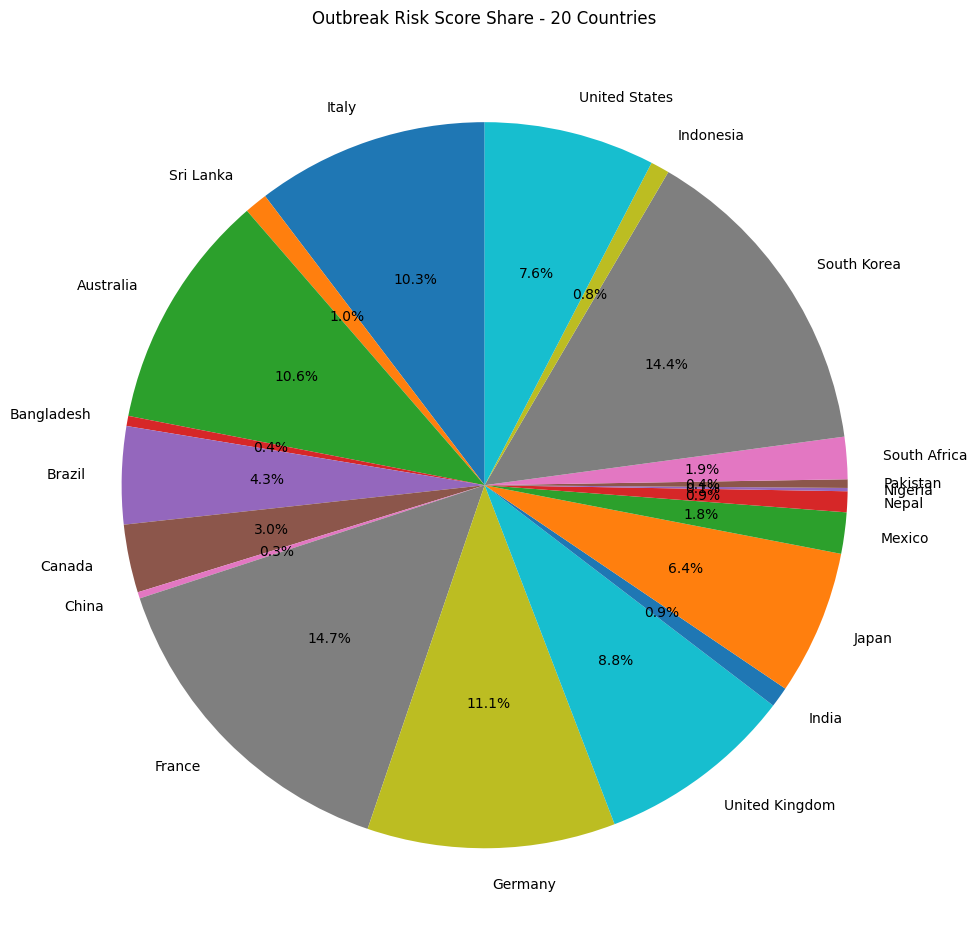

In [ ]:
# Pie Chart - Risk Score Share by Country

risk_data = (
    country_history_df
    .sort_values("date")
    .groupby("country")
    .tail(1)
)

plt.figure(figsize=(10, 10))

plt.pie(
    risk_data["risk_score"],
    labels=risk_data["country"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Outbreak Risk Score Share - 20 Countries")

plt.tight_layout()
plt.show()

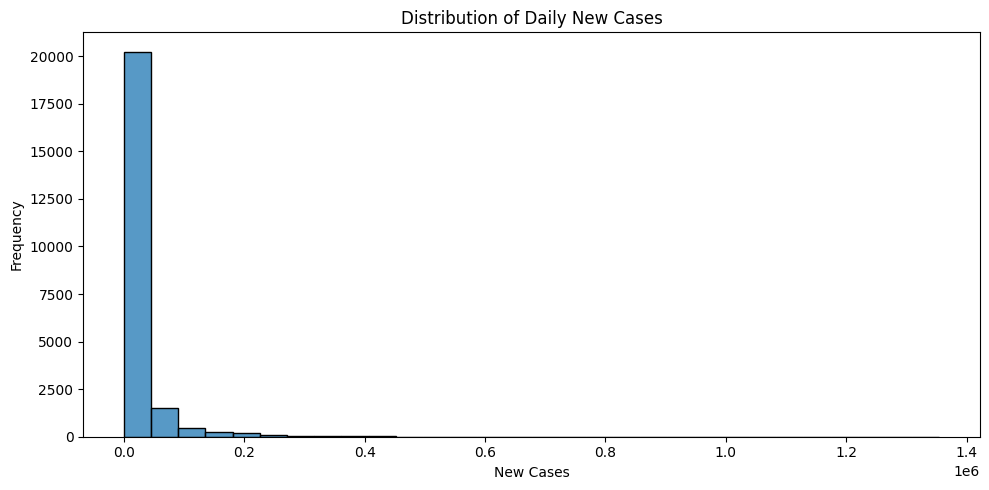

In [ ]:
# Histogram - Daily Cases Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=country_history_df,
    x="new_cases",
    bins=30
)

plt.title("Distribution of Daily New Cases")
plt.xlabel("New Cases")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

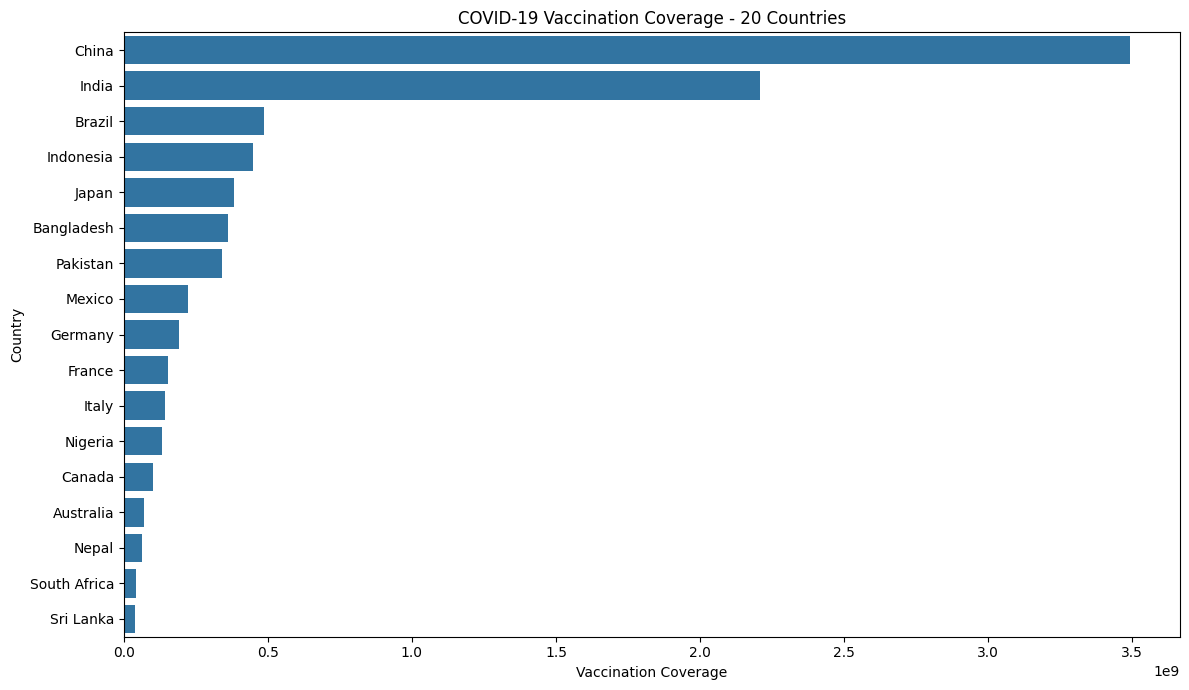

In [ ]:
# Vaccination Coverage by Country

vaccine_plot = (
    vaccine_df[vaccine_df["country"].isin(WATCHLIST)]
    .sort_values("vaccine_coverage", ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=vaccine_plot,
    x="vaccine_coverage",
    y="country"
)

plt.title("COVID-19 Vaccination Coverage - 20 Countries")
plt.xlabel("Vaccination Coverage")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

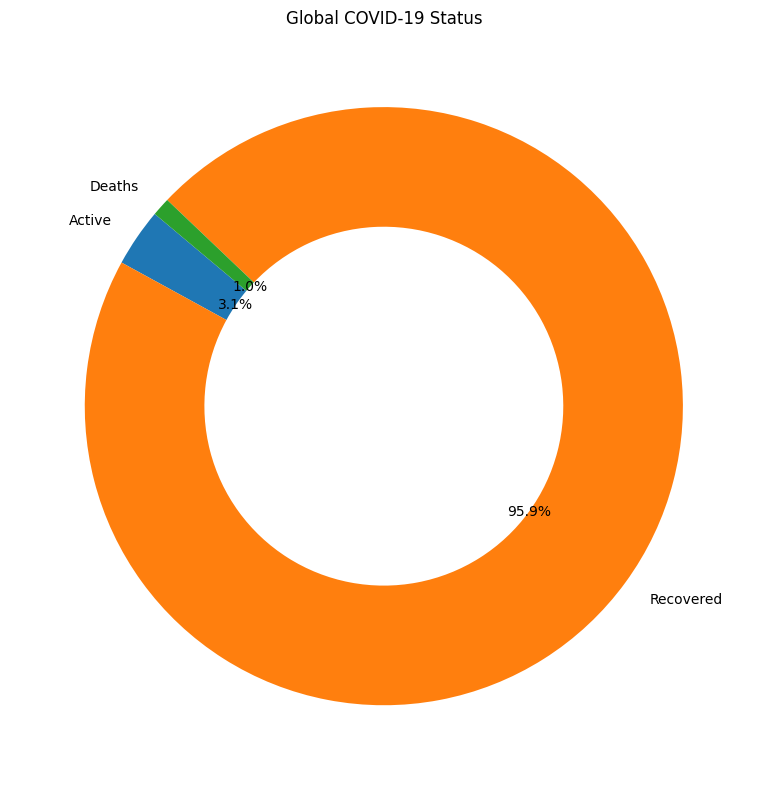

In [ ]:
# Global COVID-19 Status

status_data = pd.DataFrame({
    "Status": ["Active", "Recovered", "Deaths"],
    "Count": [
        worldwide_data["active"],
        worldwide_data["recovered"],
        worldwide_data["deaths"]
    ]
})

plt.figure(figsize=(8, 8))

plt.pie(
    status_data["Count"],
    labels=status_data["Status"],
    autopct="%1.1f%%",
    startangle=140,
    wedgeprops=dict(width=0.4)
)

plt.title("Global COVID-19 Status")

plt.tight_layout()
plt.show()

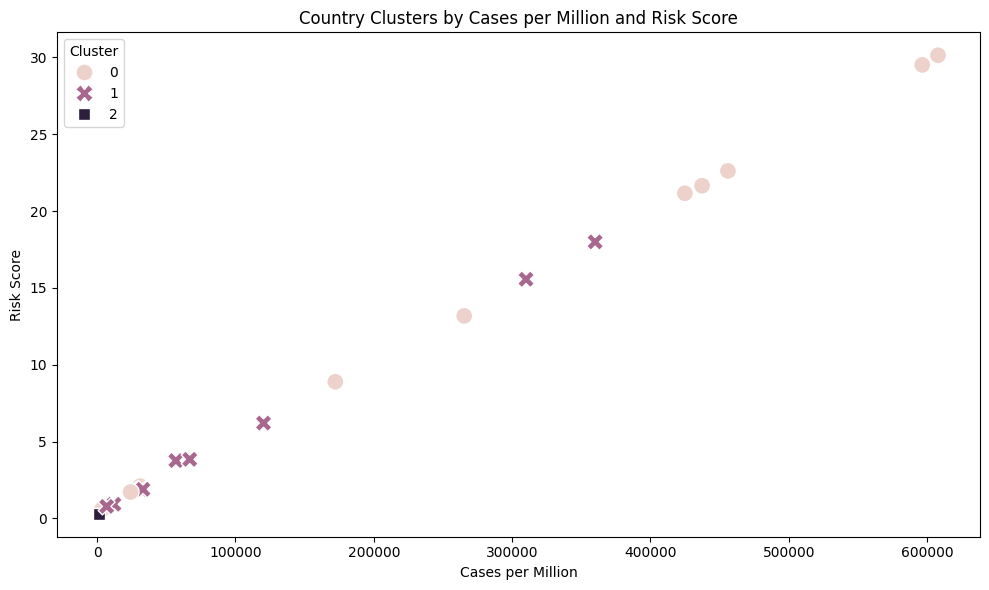

In [ ]:
# KMeans Cluster Visualization

cluster_plot = (
    country_history_df
    .sort_values("date")
    .groupby("country")
    .tail(1)
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=cluster_plot,
    x="cases_per_million",
    y="risk_score",
    hue="cluster",
    style="cluster",
    s=150
)

plt.title("Country Clusters by Cases per Million and Risk Score")
plt.xlabel("Cases per Million")
plt.ylabel("Risk Score")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

In [ ]:
#sqlite next step
#Create the database and main fact table:

import sqlite3

conn = sqlite3.connect("epidemiology.db")

cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS fact_daily_stats (
    country TEXT NOT NULL,
    date TEXT NOT NULL,
    cumulative_cases INTEGER,
    cumulative_deaths INTEGER,
    new_cases INTEGER,
    new_deaths INTEGER,
    cases_7d_avg REAL,
    deaths_7d_avg REAL,
    cases_per_million REAL,
    deaths_per_million REAL,
    growth_rate REAL,
    case_fatality_ratio REAL,
    risk_score REAL,
    cluster INTEGER,
    cases_zscore REAL,
    anomaly INTEGER,
    PRIMARY KEY (country, date)
)
""")

conn.commit()

print("SQLite database and fact_daily_stats table created successfully!")

SQLite database and fact_daily_stats table created successfully!


In [ ]:
# Create supporting SQLite tables

cursor.execute("""
CREATE TABLE IF NOT EXISTS global_snapshot (
    updated TEXT,
    cases INTEGER,
    today_cases INTEGER,
    deaths INTEGER,
    today_deaths INTEGER,
    recovered INTEGER,
    active INTEGER,
    critical INTEGER,
    affected_countries INTEGER
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS global_history (
    date TEXT PRIMARY KEY,
    cumulative_cases INTEGER,
    cumulative_deaths INTEGER,
    new_cases INTEGER,
    new_deaths INTEGER
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS vaccine_coverage (
    country TEXT NOT NULL,
    date TEXT NOT NULL,
    vaccine_coverage INTEGER,
    PRIMARY KEY (country, date)
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS alerts (
    country TEXT NOT NULL,
    date TEXT NOT NULL,
    growth_rate REAL,
    alert_message TEXT
)
""")

conn.commit()

print("All SQLite tables created successfully!")

All SQLite tables created successfully!


In [ ]:
# UPSERT cleaned country data into SQLite

upsert_query = """
INSERT INTO fact_daily_stats (
    country,
    date,
    cumulative_cases,
    cumulative_deaths,
    new_cases,
    new_deaths,
    cases_7d_avg,
    deaths_7d_avg,
    cases_per_million,
    deaths_per_million,
    growth_rate,
    case_fatality_ratio,
    risk_score,
    cluster,
    cases_zscore,
    anomaly
)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)

ON CONFLICT(country, date) DO UPDATE SET
    cumulative_cases = excluded.cumulative_cases,
    cumulative_deaths = excluded.cumulative_deaths,
    new_cases = excluded.new_cases,
    new_deaths = excluded.new_deaths,
    cases_7d_avg = excluded.cases_7d_avg,
    deaths_7d_avg = excluded.deaths_7d_avg,
    cases_per_million = excluded.cases_per_million,
    deaths_per_million = excluded.deaths_per_million,
    growth_rate = excluded.growth_rate,
    case_fatality_ratio = excluded.case_fatality_ratio,
    risk_score = excluded.risk_score,
    cluster = excluded.cluster,
    cases_zscore = excluded.cases_zscore,
    anomaly = excluded.anomaly
"""

for _, row in country_history_df.iterrows():

    cursor.execute(
        upsert_query,
        (
            row["country"],
            row["date"].strftime("%Y-%m-%d"),
            int(row["cumulative_cases"]),
            int(row["cumulative_deaths"]),
            int(row["new_cases"]),
            int(row["new_deaths"]),
            float(row["cases_7d_avg"]),
            float(row["deaths_7d_avg"]),
            float(row["cases_per_million"]),
            float(row["deaths_per_million"]),
            None if pd.isna(row["growth_rate"]) else float(row["growth_rate"]),
            float(row["case_fatality_ratio"]),
            float(row["risk_score"]),
            int(row["cluster"]),
            None if pd.isna(row["cases_zscore"]) else float(row["cases_zscore"]),
            int(row["anomaly"])
        )
    )

conn.commit()

print("UPSERT completed successfully!")
cursor.execute("SELECT COUNT(*) FROM fact_daily_stats")

count = cursor.fetchone()[0]

print("Rows in fact_daily_stats:", count)

UPSERT completed successfully!
Rows in fact_daily_stats: 22860


In [ ]:
# Create indexes for faster queries

cursor.execute("""
CREATE INDEX IF NOT EXISTS idx_fact_country_date
ON fact_daily_stats(country, date)
""")

cursor.execute("""
CREATE INDEX IF NOT EXISTS idx_fact_date
ON fact_daily_stats(date)
""")

conn.commit()

print("Indexes created successfully!")

Indexes created successfully!


In [ ]:
# Check query plan using the country + date index

query_plan = cursor.execute("""
EXPLAIN QUERY PLAN
SELECT *
FROM fact_daily_stats
WHERE country = 'India'
AND date = '2023-03-09'
""").fetchall()

for row in query_plan:
    print(row)

(3, 0, 0, 'SEARCH fact_daily_stats USING INDEX sqlite_autoindex_fact_daily_stats_1 (country=? AND date=?)')


In [ ]:
# Check indexes on fact_daily_stats

indexes = cursor.execute("""
PRAGMA index_list(fact_daily_stats)
""").fetchall()

for index in indexes:
    print(index)

(0, 'idx_fact_date', 0, 'c', 0)
(1, 'idx_fact_country_date', 0, 'c', 0)
(2, 'sqlite_autoindex_fact_daily_stats_1', 1, 'pk', 0)


In [ ]:
#Advanced Query for 7-day SQL-side moving average as a cross-check against your Pandas figure,
query1 = """
SELECT
    country,
    date,
    new_cases,
    AVG(new_cases) OVER (
        PARTITION BY country
        ORDER BY date
        ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
    ) AS sql_7d_moving_avg
FROM fact_daily_stats
WHERE country = 'China'
ORDER BY date
LIMIT 20;
"""

result1 = pd.read_sql_query(query1, conn)

display(result1)

,country,date,new_cases,sql_7d_moving_avg
0,China,2020-01-22,0,0.000000
1,China,2020-01-23,95,47.500000
2,China,2020-01-24,277,124.000000
3,China,2020-01-25,486,214.500000
4,China,2020-01-26,669,305.400000
5,China,2020-01-27,802,388.166667
6,China,2020-01-28,2632,708.714286
7,China,2020-01-29,578,791.285714
8,China,2020-01-30,2054,1071.142857
9,China,2020-01-31,1661,1268.857143


In [ ]:
#RANK() of countries by risk_score,
query2 = """
WITH latest_data AS (
    SELECT
        country,
        date,
        risk_score,
        ROW_NUMBER() OVER (
            PARTITION BY country
            ORDER BY date DESC
        ) AS rn
    FROM fact_daily_stats
)

SELECT
    country,
    date,
    risk_score,
    RANK() OVER (
        ORDER BY risk_score DESC
    ) AS risk_rank
FROM latest_data
WHERE rn = 1
ORDER BY risk_rank;
"""

result2 = pd.read_sql_query(query2, conn)

display(result2)

,country,date,risk_score,risk_rank
0,France,2023-03-09,30.133888,1
1,South Korea,2023-03-09,29.505896,2
2,Germany,2023-03-09,22.609689,3
3,Australia,2023-03-09,21.647243,4
4,Italy,2023-03-09,21.153840,5
5,United Kingdom,2023-03-09,17.992007,6
6,United States,2023-03-09,15.558908,7
7,Japan,2023-03-09,13.174492,8
8,Brazil,2023-03-09,8.887800,9
9,Canada,2023-03-09,6.200086,10


In [ ]:
#Week-over-Week % Change using CTE
query3 = """
WITH weekly_cases AS (
    SELECT
        country,
        strftime('%Y-%W', date) AS week,
        SUM(new_cases) AS weekly_cases
    FROM fact_daily_stats
    GROUP BY country, week
),

previous_week AS (
    SELECT
        country,
        week,
        weekly_cases,
        LAG(weekly_cases) OVER (
            PARTITION BY country
            ORDER BY week
        ) AS previous_week_cases
    FROM weekly_cases
)

SELECT
    country,
    week,
    weekly_cases,
    previous_week_cases,
    CASE
        WHEN previous_week_cases > 0
        THEN ROUND(
            (weekly_cases - previous_week_cases)
            * 100.0 / previous_week_cases,
            2
        )
        ELSE NULL
    END AS week_over_week_percent
FROM previous_week
ORDER BY country, week;
"""

result3 = pd.read_sql_query(query3, conn)

display(result3.head(20))

,country,week,weekly_cases,previous_week_cases,week_over_week_percent
0,Australia,2020-03,4,NaN,NaN
1,Australia,2020-04,8,4.0,100.00
2,Australia,2020-05,3,8.0,-62.50
3,Australia,2020-06,0,3.0,-100.00
4,Australia,2020-07,0,0.0,NaN
5,Australia,2020-08,12,0.0,NaN
6,Australia,2020-09,49,12.0,308.33
7,Australia,2020-10,221,49.0,351.02
8,Australia,2020-11,1252,221.0,466.52
9,Australia,2020-12,2435,1252.0,94.49


In [ ]:
#Country Latest Statistics
query4 = """
WITH latest_data AS (
    SELECT
        country,
        date,
        cumulative_cases,
        cumulative_deaths,
        new_cases,
        risk_score,
        growth_rate,
        ROW_NUMBER() OVER (
            PARTITION BY country
            ORDER BY date DESC
        ) AS rn
    FROM fact_daily_stats
)

SELECT
    country,
    date,
    cumulative_cases,
    cumulative_deaths,
    new_cases,
    risk_score,
    growth_rate
FROM latest_data
WHERE rn = 1
ORDER BY risk_score DESC;
"""

result4 = pd.read_sql_query(query4, conn)

display(result4)

,country,date,cumulative_cases,cumulative_deaths,new_cases,risk_score,growth_rate
0,France,2023-03-09,39866718,166176,6308,30.133888,18.934980
1,South Korea,2023-03-09,30615522,34093,10335,29.505896,11.386000
2,Germany,2023-03-09,38249060,168935,7829,22.609689,-58.669832
3,Australia,2023-03-09,11399460,19574,13926,21.647243,-25.357601
4,Italy,2023-03-09,25603510,188322,0,21.153840,-9.443576
5,United Kingdom,2023-03-09,24658705,220721,28783,17.992007,9.126984
6,United States,2023-03-09,103802702,1123836,46931,15.558908,-3.317339
7,Japan,2023-03-09,33320438,72997,9834,13.174492,-14.600113
8,Brazil,2023-03-09,37076053,699276,0,8.887800,-67.452311
9,Canada,2023-03-09,4617095,51720,4041,6.200086,-5.294891


In [ ]:
#vw_country_latest_snapshot
cursor.execute("""
CREATE VIEW IF NOT EXISTS vw_country_latest_snapshot AS

WITH latest_data AS (
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY country
            ORDER BY date DESC
        ) AS rn
    FROM fact_daily_stats
)

SELECT
    country,
    date,
    cumulative_cases,
    cumulative_deaths,
    new_cases,
    cases_7d_avg,
    deaths_7d_avg,
    cases_per_million,
    deaths_per_million,
    growth_rate,
    case_fatality_ratio,
    risk_score,
    cluster,
    cases_zscore,
    anomaly

FROM latest_data
WHERE rn = 1;
""")

conn.commit()

print("View 1 created successfully!")

pd.read_sql_query("""
SELECT *
FROM vw_country_latest_snapshot
ORDER BY risk_score DESC;
""", conn)

View 1 created successfully!


,country,date,cumulative_cases,cumulative_deaths,new_cases,cases_7d_avg,deaths_7d_avg,cases_per_million,deaths_per_million,growth_rate,case_fatality_ratio,risk_score,cluster,cases_zscore,anomaly
0,France,2023-03-09,39866718,166176,6308,4403.142857,18.000000,607867.820268,2533.768717,18.934980,0.416829,30.133888,0,-0.443969,0
1,South Korea,2023-03-09,30615522,34093,10335,10220.142857,11.285714,596446.176526,664.193787,11.386000,0.111359,29.505896,0,-0.257931,0
2,Germany,2023-03-09,38249060,168935,7829,6641.285714,91.285714,455977.829086,2013.921768,-58.669832,0.441671,22.609689,0,-0.396378,0
3,Australia,2023-03-09,11399460,19574,13926,2079.857143,16.571429,437283.783614,750.859495,-25.357601,0.171710,21.647243,0,0.202372,0
4,Italy,2023-03-09,25603510,188322,0,3808.285714,32.571429,424864.472708,3125.014001,-9.443576,0.735532,21.153840,0,-0.607115,0
5,United Kingdom,2023-03-09,24658705,220721,28783,4125.000000,0.000000,359992.094357,3222.302836,9.126984,0.895104,17.992007,1,0.176260,0
6,United States,2023-03-09,103802702,1123836,46931,30972.428571,316.571429,310039.033466,3356.685525,-3.317339,1.082665,15.558908,1,-0.346822,0
7,Japan,2023-03-09,33320438,72997,9834,9678.857143,59.428571,265322.140241,581.256473,-14.600113,0.219076,13.174492,0,-0.378876,0
8,Brazil,2023-03-09,37076053,699276,0,2535.000000,11.285714,172163.614656,3247.106260,-67.452311,1.886058,8.887800,0,-0.937804,0
9,Canada,2023-03-09,4617095,51720,4041,1234.142857,26.285714,120273.121954,1347.281325,-5.294891,1.120185,6.200086,1,-0.001969,0


In [ ]:
#View 2 — Risk Ranking

cursor.execute("""
CREATE VIEW IF NOT EXISTS vw_risk_ranking AS

WITH latest_data AS (
    SELECT
        country,
        date,
        risk_score,
        growth_rate,
        cases_per_million,
        case_fatality_ratio,
        ROW_NUMBER() OVER (
            PARTITION BY country
            ORDER BY date DESC
        ) AS rn
    FROM fact_daily_stats
)

SELECT
    country,
    date,
    risk_score,
    growth_rate,
    cases_per_million,
    case_fatality_ratio,
    RANK() OVER (
        ORDER BY risk_score DESC
    ) AS risk_rank
FROM latest_data
WHERE rn = 1
ORDER BY risk_rank;
""")

conn.commit()

print("View 2 created successfully!")

pd.read_sql_query("""
SELECT *
FROM vw_risk_ranking;
""", conn)

View 2 created successfully!


,country,date,risk_score,growth_rate,cases_per_million,case_fatality_ratio,risk_rank
0,France,2023-03-09,30.133888,18.934980,607867.820268,0.416829,1
1,South Korea,2023-03-09,29.505896,11.386000,596446.176526,0.111359,2
2,Germany,2023-03-09,22.609689,-58.669832,455977.829086,0.441671,3
3,Australia,2023-03-09,21.647243,-25.357601,437283.783614,0.171710,4
4,Italy,2023-03-09,21.153840,-9.443576,424864.472708,0.735532,5
5,United Kingdom,2023-03-09,17.992007,9.126984,359992.094357,0.895104,6
6,United States,2023-03-09,15.558908,-3.317339,310039.033466,1.082665,7
7,Japan,2023-03-09,13.174492,-14.600113,265322.140241,0.219076,8
8,Brazil,2023-03-09,8.887800,-67.452311,172163.614656,1.886058,9
9,Canada,2023-03-09,6.200086,-5.294891,120273.121954,1.120185,10


In [ ]:
#View 3 — Weekly Trend
cursor.execute("""
CREATE VIEW IF NOT EXISTS vw_weekly_trend AS

SELECT
    country,
    strftime('%Y-%W', date) AS week,
    SUM(new_cases) AS weekly_cases,
    SUM(new_deaths) AS weekly_deaths,
    AVG(cases_7d_avg) AS avg_7d_cases,
    AVG(risk_score) AS avg_risk_score

FROM fact_daily_stats

GROUP BY country, week
ORDER BY country, week;
""")

conn.commit()

print("View 3 created successfully!")
pd.read_sql_query("""
SELECT *
FROM vw_weekly_trend
LIMIT 20;
""", conn)

View 3 created successfully!


,country,week,weekly_cases,weekly_deaths,avg_7d_cases,avg_risk_score
0,Australia,2020-03,4,0,0.000000,0.042480
1,Australia,2020-04,8,0,1.000000,0.042494
2,Australia,2020-05,3,0,0.795918,0.034093
3,Australia,2020-06,0,0,0.163265,0.007094
4,Australia,2020-07,0,0,0.000000,0.018234
5,Australia,2020-08,12,1,0.448980,0.148333
6,Australia,2020-09,49,2,5.061224,0.759290
7,Australia,2020-10,221,0,16.857143,0.556078
8,Australia,2020-11,1252,4,87.510204,0.395031
9,Australia,2020-12,2435,9,289.346939,0.244326


In [ ]:
import pandas as pd
from datetime import datetime, timedelta

def simulate_daily_run():

    # Get latest date in SQLite
    latest_date = cursor.execute("""
        SELECT MAX(date)
        FROM fact_daily_stats
    """).fetchone()[0]

    latest_date = datetime.strptime(latest_date, "%Y-%m-%d").date()
    new_date = latest_date + timedelta(days=1)

    print("\n" + "="*60)
    print("Daily pipeline started")
    print("Previous latest date:", latest_date)
    print("New simulated date:", new_date)

    # Get the latest record for every country
    query = """
    SELECT *
    FROM fact_daily_stats
    WHERE date = ?
    """

    df = pd.read_sql_query(
        query,
        conn,
        params=(latest_date.strftime("%Y-%m-%d"),)
    )

    rows_inserted = 0

    for _, row in df.iterrows():

        new_cases = int(row["new_cases"] or 0)
        new_deaths = int(row["new_deaths"] or 0)

        # Simulated cumulative values
        cumulative_cases = int(row["cumulative_cases"] or 0) + new_cases
        cumulative_deaths = int(row["cumulative_deaths"] or 0) + new_deaths

        cursor.execute("""
            INSERT INTO fact_daily_stats (
                country,
                date,
                cumulative_cases,
                cumulative_deaths,
                new_cases,
                new_deaths,
                cases_7d_avg,
                deaths_7d_avg,
                cases_per_million,
                deaths_per_million,
                growth_rate,
                case_fatality_ratio,
                risk_score,
                cluster,
                cases_zscore,
                anomaly
            )
            VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
        """, (
            row["country"],
            new_date.strftime("%Y-%m-%d"),
            cumulative_cases,
            cumulative_deaths,
            new_cases,
            new_deaths,
            row["cases_7d_avg"],
            row["deaths_7d_avg"],
            row["cases_per_million"],
            row["deaths_per_million"],
            row["growth_rate"],
            row["case_fatality_ratio"],
            row["risk_score"],
            row["cluster"],
            row["cases_zscore"],
            row["anomaly"]
        ))

        rows_inserted += 1

    conn.commit()

    print("Rows inserted:", rows_inserted)
    print("Pipeline completed successfully.")
    print("Latest date now:", new_date)


# Simulate 5 consecutive daily runs
for day in range(1, 6):
    print(f"\n========== SIMULATED DAY {day} ==========")
    simulate_daily_run()


========== SIMULATED DAY 1 ==========

Daily pipeline started
Previous latest date: 2023-03-09
New simulated date: 2023-03-10
Rows inserted: 20
Pipeline completed successfully.
Latest date now: 2023-03-10

========== SIMULATED DAY 2 ==========

Daily pipeline started
Previous latest date: 2023-03-10
New simulated date: 2023-03-11
Rows inserted: 20
Pipeline completed successfully.
Latest date now: 2023-03-11

========== SIMULATED DAY 3 ==========

Daily pipeline started
Previous latest date: 2023-03-11
New simulated date: 2023-03-12
Rows inserted: 20
Pipeline completed successfully.
Latest date now: 2023-03-12

========== SIMULATED DAY 4 ==========

Daily pipeline started
Previous latest date: 2023-03-12
New simulated date: 2023-03-13
Rows inserted: 20
Pipeline completed successfully.
Latest date now: 2023-03-13

========== SIMULATED DAY 5 ==========

Daily pipeline started
Previous latest date: 2023-03-13
New simulated date: 2023-03-14
Rows inserted: 20
Pipeline completed successfully

In [ ]:
cursor.execute("PRAGMA table_info(alerts)")
alerts_schema = cursor.fetchall()

for column in alerts_schema:
    print(column)

(0, 'country', 'TEXT', 1, None, 0)
(1, 'date', 'TEXT', 1, None, 0)
(2, 'growth_rate', 'REAL', 0, None, 0)
(3, 'alert_message', 'TEXT', 0, None, 0)


In [ ]:
# Get the latest date in the database
latest_date = cursor.execute("""
    SELECT MAX(date)
    FROM fact_daily_stats
""").fetchone()[0]

threshold = 10

# Check only the latest day's growth
alerts_df = pd.read_sql_query("""
    SELECT country, date, growth_rate
    FROM fact_daily_stats
    WHERE date = ?
      AND growth_rate > ?
    ORDER BY growth_rate DESC
""", conn, params=(latest_date, threshold))

print("Latest date:", latest_date)
print("Countries exceeding 10% growth:")
display(alerts_df)

Latest date: 2023-03-14
Countries exceeding 10% growth:


,country,date,growth_rate
0,India,2023-03-14,52.005175
1,Mexico,2023-03-14,41.145490
2,Sri Lanka,2023-03-14,33.333333
3,Pakistan,2023-03-14,22.382671
4,France,2023-03-14,18.934980
5,South Korea,2023-03-14,11.386000


In [ ]:
cursor.execute("DELETE FROM alerts")
conn.commit()

print("Old alerts cleared.")

Old alerts cleared.


In [ ]:
for _, row in alerts_df.iterrows():

    cursor.execute("""
        INSERT INTO alerts (
            country,
            date,
            growth_rate,
            alert_message
        )
        VALUES (?, ?, ?, ?)
    """, (
        row["country"],
        row["date"],
        row["growth_rate"],
        f"7-day case growth exceeded {threshold}%"
    ))

conn.commit()

print("Alerts inserted:", len(alerts_df))

Alerts inserted: 6


In [ ]:
pd.read_sql_query("""
SELECT *
FROM alerts
ORDER BY date DESC
""", conn)

,country,date,growth_rate,alert_message
0,India,2023-03-14,52.005175,7-day case growth exceeded 10%
1,Mexico,2023-03-14,41.145490,7-day case growth exceeded 10%
2,Sri Lanka,2023-03-14,33.333333,7-day case growth exceeded 10%
3,Pakistan,2023-03-14,22.382671,7-day case growth exceeded 10%
4,France,2023-03-14,18.934980,7-day case growth exceeded 10%
5,South Korea,2023-03-14,11.386000,7-day case growth exceeded 10%


In [ ]:
import requests
import pandas as pd
from datetime import datetime

# 1. GLOBAL SNAPSHOT
url = "https://disease.sh/v3/covid-19/all"
r = requests.get(url, timeout=30)
r.raise_for_status()
data = r.json()

cursor.execute("DELETE FROM global_snapshot")

cursor.execute("""
INSERT INTO global_snapshot (
    updated, cases, today_cases, deaths, today_deaths,
    recovered, active, critical, affected_countries
)
VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)
""", (
    str(datetime.fromtimestamp(data["updated"] / 1000)),
    data["cases"],
    data["todayCases"],
    data["deaths"],
    data["todayDeaths"],
    data["recovered"],
    data["active"],
    data["critical"],
    data["affectedCountries"]
))


# 2. GLOBAL HISTORICAL DATA
url = "https://disease.sh/v3/covid-19/historical/all?lastdays=all"
r = requests.get(url, timeout=60)
r.raise_for_status()
data = r.json()

global_df = pd.DataFrame({
    "date": list(data["cases"].keys()),
    "cumulative_cases": list(data["cases"].values()),
    "cumulative_deaths": list(data["deaths"].values())
})

global_df["date"] = pd.to_datetime(
    global_df["date"], format="%m/%d/%y"
).dt.strftime("%Y-%m-%d")

global_df = global_df.sort_values("date")

global_df["new_cases"] = (
    global_df["cumulative_cases"].diff().fillna(0).clip(lower=0)
)

global_df["new_deaths"] = (
    global_df["cumulative_deaths"].diff().fillna(0).clip(lower=0)
)

cursor.execute("DELETE FROM global_history")

for _, row in global_df.iterrows():
    cursor.execute("""
    INSERT INTO global_history (
        date, cumulative_cases, cumulative_deaths,
        new_cases, new_deaths
    )
    VALUES (?, ?, ?, ?, ?)
    """, (
        row["date"],
        int(row["cumulative_cases"]),
        int(row["cumulative_deaths"]),
        int(row["new_cases"]),
        int(row["new_deaths"])
    ))


# 3. VACCINE COVERAGE
url = "https://disease.sh/v3/covid-19/vaccine/coverage/countries?lastdays=1"
r = requests.get(url, timeout=60)
r.raise_for_status()
vaccine_data = r.json()

cursor.execute("DELETE FROM vaccine_coverage")

for record in vaccine_data:
    country = record["country"]

    for date, coverage in record["timeline"].items():
        date_formatted = datetime.strptime(
            date, "%m/%d/%y"
        ).strftime("%Y-%m-%d")

        cursor.execute("""
        INSERT INTO vaccine_coverage (
            country, date, vaccine_coverage
        )
        VALUES (?, ?, ?)
        """, (country, date_formatted, coverage))


conn.commit()

print("All three tables populated successfully!")

All three tables populated successfully!


In [ ]:
import sqlite3

conn = sqlite3.connect("epidemiology.db")
cursor = conn.cursor()

for table in [
    "global_snapshot",
    "global_history",
    "vaccine_coverage"
]:
    count = cursor.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    print(f"{table}: {count} rows")

global_snapshot: 1 rows
global_history: 1143 rows
vaccine_coverage: 217 rows


In [ ]:
import pandas as pd
from google.colab import files

tables = [
    "fact_daily_stats",
    "global_snapshot",
    "global_history",
    "vaccine_coverage",
    "alerts"
]

with pd.ExcelWriter(
    "epidemiology_powerbi.xlsx",
    engine="openpyxl"
) as writer:

    for table in tables:
        df = pd.read_sql_query(
            f"SELECT * FROM {table}",
            conn
        )

        df.to_excel(
            writer,
            sheet_name=table,
            index=False
        )

        print(f"{table}: {len(df)} rows exported")

print("Excel export completed!")

files.download("epidemiology_powerbi.xlsx")

fact_daily_stats: 22860 rows exported
global_snapshot: 1 rows exported
global_history: 1143 rows exported
vaccine_coverage: 217 rows exported
alerts: 6223 rows exported
Excel export completed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>